In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from pathlib import Path

sns.set_theme(style="whitegrid")

pd.set_option("display.max_columns", None)

file_path = Path(
    "../05_Clean_Data/marketing_data_clean.csv"
)

df = pd.read_csv(file_path)

print("Dataset Shape:", df.shape)

display(df.head())

Dataset Shape: (2240, 46)


,ID,Year_Birth,Education,Marital_Status,Income,Kidhome,Teenhome,Dt_Customer,Recency,MntWines,MntFruits,MntMeatProducts,MntFishProducts,MntSweetProducts,MntGoldProds,NumDealsPurchases,NumWebPurchases,NumCatalogPurchases,NumStorePurchases,NumWebVisitsMonth,AcceptedCmp3,AcceptedCmp4,AcceptedCmp5,AcceptedCmp1,AcceptedCmp2,Response,Complain,Country,Income_Was_Missing,Income_Imputed,Education_Standardized,Marital_Status_Group,Country_Standardized,Income_Is_Outlier,Total_Spending,Total_Purchases,Total_Children,Total_Accepted_Campaigns,Customer_Age_Estimated,Age_Group,Income_Group,Enrollment_Year,Enrollment_Month,Enrollment_Quarter,Enrollment_Month_Name,Customer_Tenure_Days
0,1826,1970,Graduation,Divorced,84835.0,0,0,2014-06-16,0,189,104,379,111,189,218,1,4,4,6,1,0,0,0,0,0,1,0,Spain,0,84835.0,Graduate,Divorced,Spain,0,1190,14,0,1,44,35-44,High Income,2014,6,2,June,14
1,1,1961,Graduation,Single,57091.0,0,0,2014-06-15,0,464,5,64,7,0,37,1,7,3,7,5,0,0,0,0,1,1,0,Canada,0,57091.0,Graduate,Single,Canada,0,577,17,0,2,53,45-54,Upper-Middle Income,2014,6,2,June,15
2,10476,1958,Graduation,Married,67267.0,0,1,2014-05-13,0,134,11,59,15,2,30,1,3,2,5,2,0,0,0,0,0,0,0,USA,0,67267.0,Graduate,Married,Usa,0,251,10,1,0,56,55-64,Upper-Middle Income,2014,5,2,May,48
3,1386,1967,Graduation,Together,32474.0,1,1,2014-05-11,0,10,0,1,0,0,0,1,1,0,2,7,0,0,0,0,0,0,0,Australia,0,32474.0,Graduate,Partnered,Australia,0,11,3,2,0,47,45-54,Low Income,2014,5,2,May,50
4,5371,1989,Graduation,Single,21474.0,1,0,2014-04-08,0,6,16,24,11,0,34,2,3,1,2,7,1,0,0,0,0,1,0,Spain,0,21474.0,Graduate,Single,Spain,0,91,6,1,2,25,25-34,Low Income,2014,4,2,April,83


In [2]:
product_columns = [
    "MntWines",
    "MntFruits",
    "MntMeatProducts",
    "MntFishProducts",
    "MntSweetProducts",
    "MntGoldProds"
]

product_names = {
    "MntWines": "Wines",
    "MntFruits": "Fruits",
    "MntMeatProducts": "Meat Products",
    "MntFishProducts": "Fish Products",
    "MntSweetProducts": "Sweet Products",
    "MntGoldProds": "Gold Products"
}

In [3]:
display(
    df[product_columns].describe().T
)

,count,mean,std,min,25%,50%,75%,max
MntWines,2240.0,303.935714,336.597393,0.0,23.75,173.5,504.25,1493.0
MntFruits,2240.0,26.302232,39.773434,0.0,1.00,8.0,33.00,199.0
MntMeatProducts,2240.0,166.950000,225.715373,0.0,16.00,67.0,232.00,1725.0
MntFishProducts,2240.0,37.525446,54.628979,0.0,3.00,12.0,50.00,259.0
MntSweetProducts,2240.0,27.062946,41.280498,0.0,1.00,8.0,33.00,263.0
MntGoldProds,2240.0,44.021875,52.167439,0.0,9.00,24.0,56.00,362.0


In [4]:
category_spending = (
    df[product_columns]
    .sum()
    .reset_index()
)

category_spending.columns = [
    "Product_Category",
    "Total_Spending"
]

category_spending["Product_Category"] = (
    category_spending["Product_Category"]
    .replace(product_names)
)

category_spending = category_spending.sort_values(
    "Total_Spending",
    ascending=False
)

display(category_spending)

,Product_Category,Total_Spending
0,Wines,680816
2,Meat Products,373968
5,Gold Products,98609
3,Fish Products,84057
4,Sweet Products,60621
1,Fruits,58917


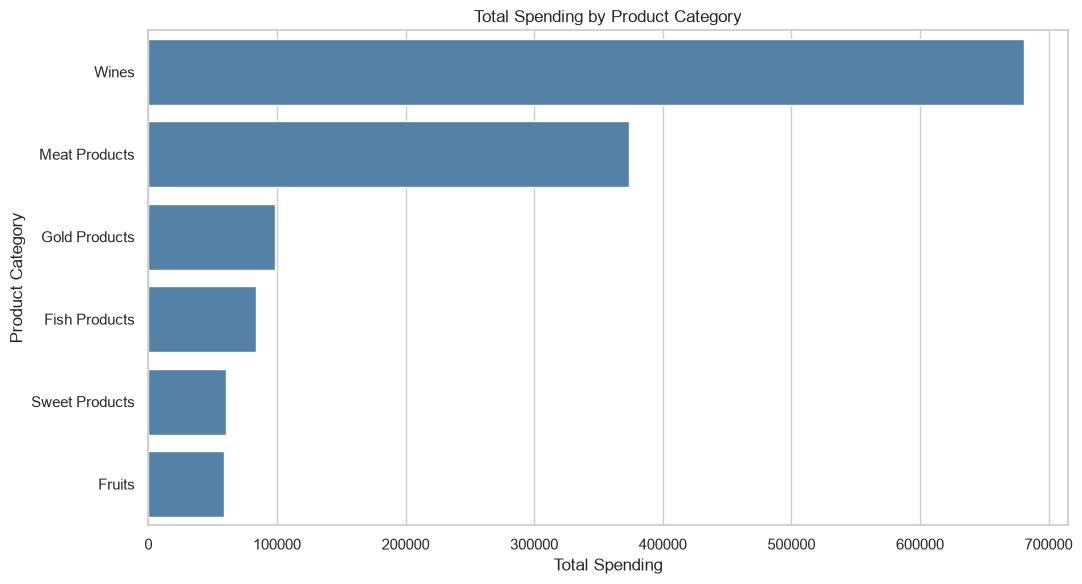

In [5]:
plt.figure(figsize=(11, 6))

sns.barplot(
    data=category_spending,
    x="Total_Spending",
    y="Product_Category",
    color="steelblue"
)

plt.title("Total Spending by Product Category")
plt.xlabel("Total Spending")
plt.ylabel("Product Category")

plt.tight_layout()
plt.show()

In [6]:
total_product_spending = (
    category_spending["Total_Spending"].sum()
)

category_spending["Spending_Share"] = (
    category_spending["Total_Spending"]
    / total_product_spending
    * 100
).round(2)

display(category_spending)

,Product_Category,Total_Spending,Spending_Share
0,Wines,680816,50.17
2,Meat Products,373968,27.56
5,Gold Products,98609,7.27
3,Fish Products,84057,6.19
4,Sweet Products,60621,4.47
1,Fruits,58917,4.34


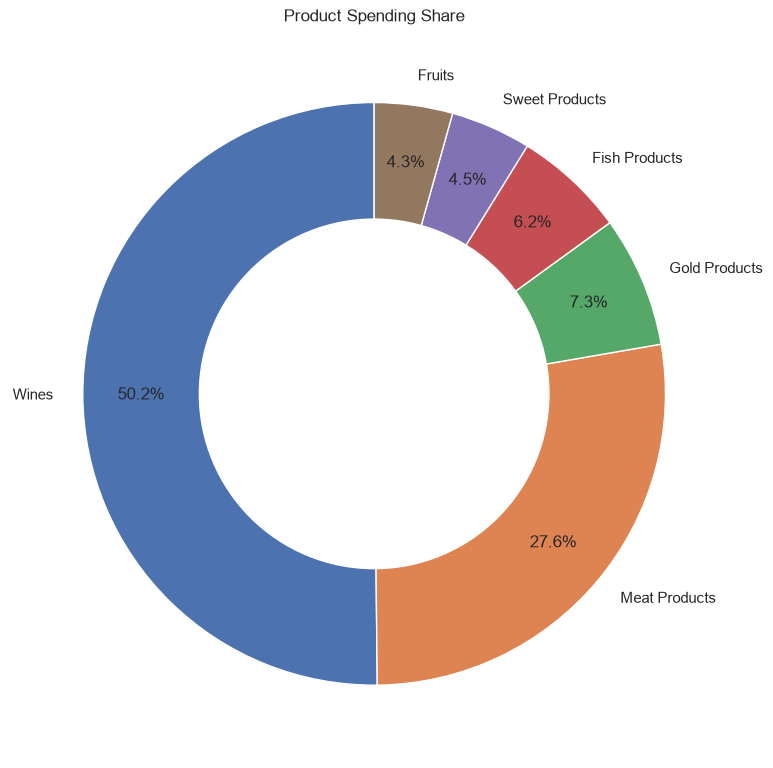

In [7]:
plt.figure(figsize=(8, 8))

plt.pie(
    category_spending["Total_Spending"],
    labels=category_spending["Product_Category"],
    autopct="%1.1f%%",
    startangle=90,
    pctdistance=0.8
)

centre_circle = plt.Circle(
    (0, 0),
    0.60,
    fc="white"
)

fig = plt.gcf()
fig.gca().add_artist(centre_circle)

plt.title("Product Spending Share")

plt.tight_layout()
plt.show()

In [8]:
customer_counts = (
    df[product_columns] > 0
).sum()

customer_counts = (
    customer_counts
    .reset_index()
)

customer_counts.columns = [
    "Product_Category",
    "Customer_Count"
]

customer_counts["Product_Category"] = (
    customer_counts["Product_Category"]
    .replace(product_names)
)

display(customer_counts)

,Product_Category,Customer_Count
0,Wines,2227
1,Fruits,1840
2,Meat Products,2239
3,Fish Products,1856
4,Sweet Products,1821
5,Gold Products,2179


In [9]:
category_performance = category_spending.merge(
    customer_counts,
    on="Product_Category",
    how="left"
)

category_performance["Avg_Spending_Per_Buyer"] = (
    category_performance["Total_Spending"]
    / category_performance["Customer_Count"].replace(0, np.nan)
)

display(category_performance.round(2))

,Product_Category,Total_Spending,Spending_Share,Customer_Count,Avg_Spending_Per_Buyer
0,Wines,680816,50.17,2227,305.71
1,Meat Products,373968,27.56,2239,167.02
2,Gold Products,98609,7.27,2179,45.25
3,Fish Products,84057,6.19,1856,45.29
4,Sweet Products,60621,4.47,1821,33.29
5,Fruits,58917,4.34,1840,32.02


In [10]:
product_long = df.melt(
    id_vars=["ID"],
    value_vars=product_columns,
    var_name="Product_Category",
    value_name="Spending"
)

product_long["Product_Category"] = (
    product_long["Product_Category"]
    .replace(product_names)
)

display(product_long.head(10))

,ID,Product_Category,Spending
0,1826,Wines,189
1,1,Wines,464
2,10476,Wines,134
3,1386,Wines,10
4,5371,Wines,6
5,7348,Wines,336
6,4073,Wines,769
7,1991,Wines,78
8,4047,Wines,384
9,9477,Wines,384


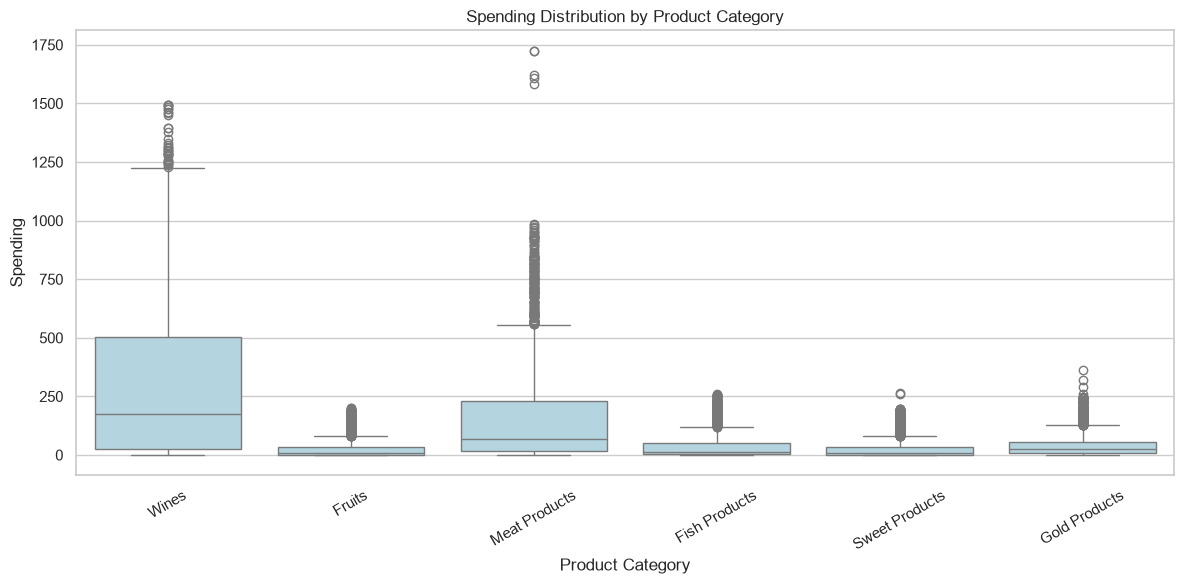

In [11]:
plt.figure(figsize=(12, 6))

sns.boxplot(
    data=product_long,
    x="Product_Category",
    y="Spending",
    color="lightblue"
)

plt.title("Spending Distribution by Product Category")
plt.xlabel("Product Category")
plt.ylabel("Spending")

plt.xticks(rotation=30)

plt.tight_layout()
plt.show()

In [12]:
age_product_spending = (
    df.groupby(
        "Age_Group",
        observed=True
    )[product_columns]
    .mean()
)

age_product_spending = (
    age_product_spending
    .rename(columns=product_names)
)

display(age_product_spending.round(2))

,Wines,Fruits,Meat Products,Fish Products,Sweet Products,Gold Products
Age_Group,,,,,,
18-24,333.10,38.69,291.02,53.20,35.43,59.15
25-34,235.21,26.93,165.79,36.97,27.70,39.66
35-44,257.16,23.37,145.19,33.40,25.09,39.01
45-54,334.65,26.30,156.20,35.03,25.19,46.04
55-64,351.00,26.52,176.55,41.07,28.00,50.48
65+,497.58,35.85,259.54,55.51,38.70,46.46


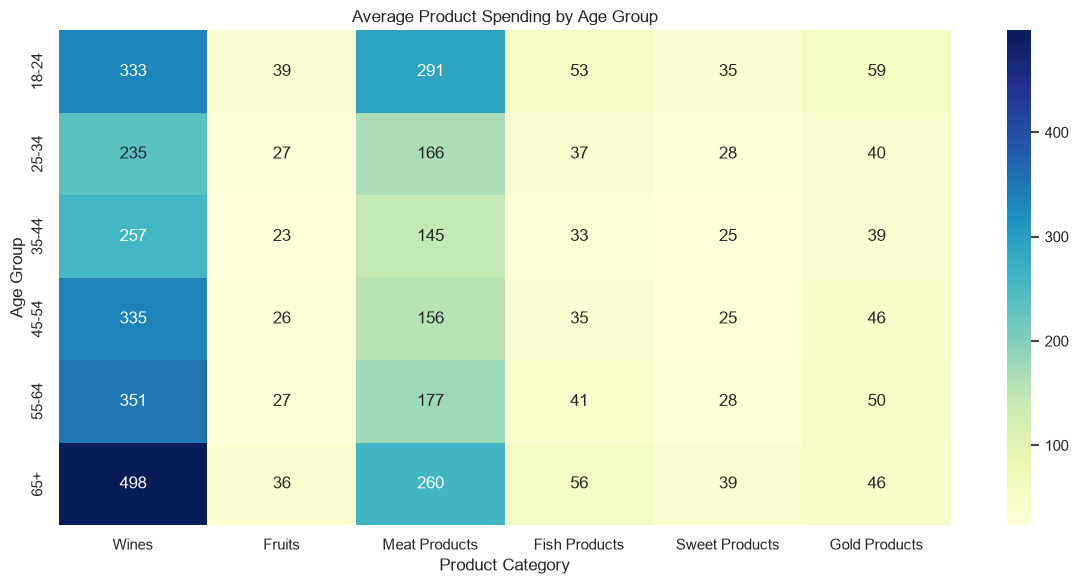

In [13]:
plt.figure(figsize=(12, 6))

sns.heatmap(
    age_product_spending,
    annot=True,
    fmt=".0f",
    cmap="YlGnBu"
)

plt.title("Average Product Spending by Age Group")
plt.xlabel("Product Category")
plt.ylabel("Age Group")

plt.tight_layout()
plt.show()

In [14]:
income_product_spending = (
    df.groupby(
        "Income_Group",
        observed=True
    )[product_columns]
    .mean()
)

income_product_spending = (
    income_product_spending
    .rename(columns=product_names)
)

display(income_product_spending.round(2))

,Wines,Fruits,Meat Products,Fish Products,Sweet Products,Gold Products
Income_Group,,,,,,
High Income,634.76,60.79,435.99,88.73,65.08,72.30
Low Income,21.55,5.94,22.67,8.67,5.92,16.85
Lower-Middle Income,124.82,8.03,48.24,13.59,8.55,28.09
Upper-Middle Income,439.23,30.67,161.09,39.56,28.57,58.62


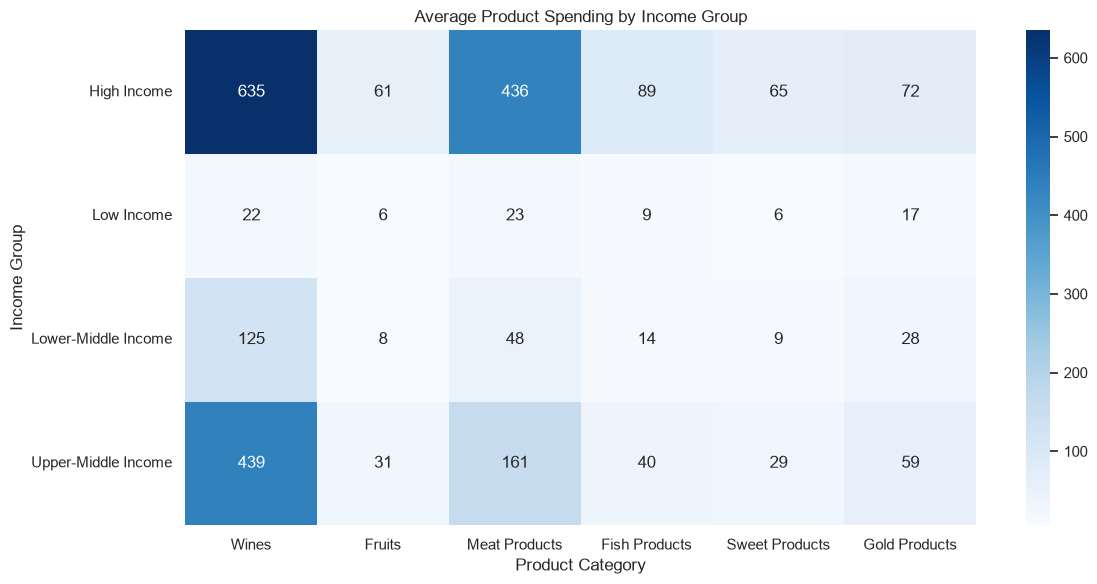

In [15]:
plt.figure(figsize=(12, 6))

sns.heatmap(
    income_product_spending,
    annot=True,
    fmt=".0f",
    cmap="Blues"
)

plt.title("Average Product Spending by Income Group")
plt.xlabel("Product Category")
plt.ylabel("Income Group")

plt.tight_layout()
plt.show()

In [16]:
spending_threshold = (
    df["Total_Spending"].quantile(0.75)
)

df["Customer_Value_Segment"] = np.where(
    df["Total_Spending"] > spending_threshold,
    "High Value",
    "Regular"
)

display(
    df["Customer_Value_Segment"].value_counts()
)

Customer_Value_Segment
Regular       1680
High Value     560
Name: count, dtype: int64

In [17]:
high_value_analysis = (
    df.groupby("Customer_Value_Segment")[product_columns]
    .mean()
)

high_value_analysis = (
    high_value_analysis
    .rename(columns=product_names)
)

display(high_value_analysis.round(2))

,Wines,Fruits,Meat Products,Fish Products,Sweet Products,Gold Products
Customer_Value_Segment,,,,,,
High Value,739.27,62.11,456.79,89.47,63.89,78.93
Regular,158.82,14.37,70.34,20.21,14.79,32.39


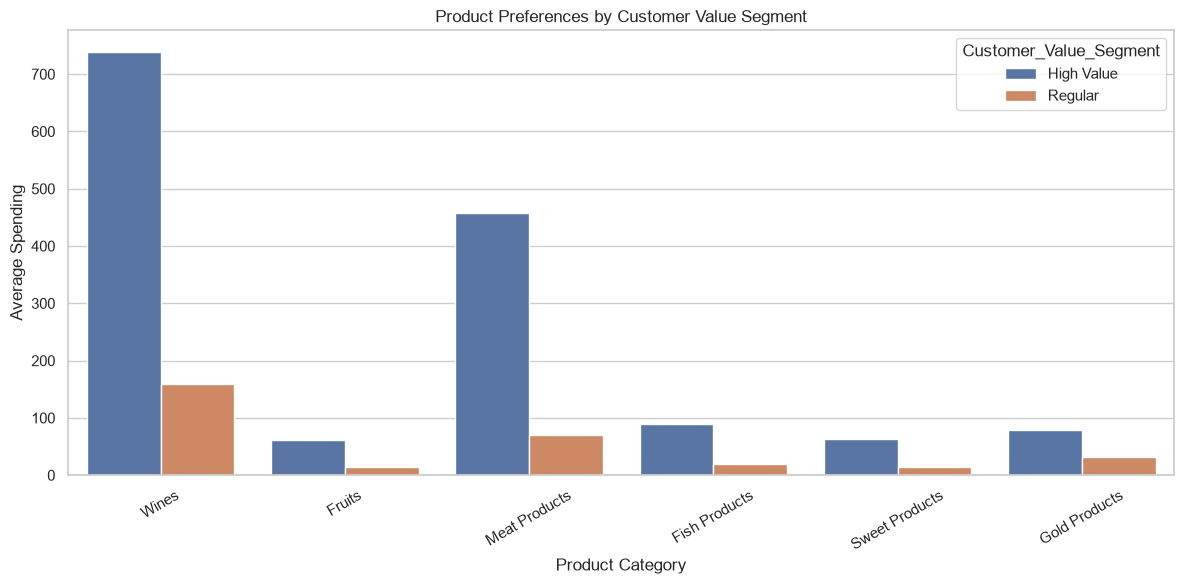

In [18]:
high_value_long = (
    high_value_analysis
    .reset_index()
    .melt(
        id_vars="Customer_Value_Segment",
        var_name="Product_Category",
        value_name="Avg_Spending"
    )
)

plt.figure(figsize=(12, 6))

sns.barplot(
    data=high_value_long,
    x="Product_Category",
    y="Avg_Spending",
    hue="Customer_Value_Segment"
)

plt.title("Product Preferences by Customer Value Segment")
plt.xlabel("Product Category")
plt.ylabel("Average Spending")

plt.xticks(rotation=30)

plt.tight_layout()
plt.show()

In [19]:
calculated_total = (
    df[product_columns].sum(axis=1)
)

difference = (
    df["Total_Spending"] - calculated_total
)

print(
    "Records with Spending Difference:",
    (difference.abs() > 0.000001).sum()
)

Records with Spending Difference: 0


In [20]:
print(
    "Total Spending from Categories:",
    df[product_columns].sum().sum()
)

print(
    "Total Spending from Derived Column:",
    df["Total_Spending"].sum()
)

Total Spending from Categories: 1356988
Total Spending from Derived Column: 1356988


In [21]:
product_performance_summary = (
    category_performance[
        [
            "Product_Category",
            "Total_Spending",
            "Spending_Share",
            "Customer_Count",
            "Avg_Spending_Per_Buyer"
        ]
    ]
    .sort_values(
        "Total_Spending",
        ascending=False
    )
)

display(
    product_performance_summary.round(2)
)

,Product_Category,Total_Spending,Spending_Share,Customer_Count,Avg_Spending_Per_Buyer
0,Wines,680816,50.17,2227,305.71
1,Meat Products,373968,27.56,2239,167.02
2,Gold Products,98609,7.27,2179,45.25
3,Fish Products,84057,6.19,1856,45.29
4,Sweet Products,60621,4.47,1821,33.29
5,Fruits,58917,4.34,1840,32.02
